# HMRW Hyperparameter Study (Single Large Synthetic Hypergraph)

This notebook generates one large synthetic hypergraph once, then evaluates only
`hmrw_embeddings` under different hyperparameters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.synthetic import generate_dataset
from src.utils import hmrw_embeddings

In [2]:
def evaluate_embeddings(X, y, seed=42, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=3000)
    scores = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring={"micro_f1": "f1_micro", "macro_f1": "f1_macro"},
        n_jobs=-1,
        return_train_score=False,
    )
    return float(np.mean(scores["test_micro_f1"])), float(np.mean(scores["test_macro_f1"]))

In [3]:
# --- Generate one large synthetic hypergraph once ---
data_seed = 777
data_params = dict(
    n=1000,
    avg_degree=12,
    num_communities=3,
    intra_strength=0.8,
    avg_edge_size=4,
    max_hyperedge_size=10,
)

sample = generate_dataset(seed=data_seed, **data_params)
H = sample["H"]
nodes = sorted(H.get_nodes())
y = np.array([sample["g1"][u] for u in nodes])

print(f"Generated H with {len(nodes)} nodes, {len(H.get_edges())} hyperedges")

generate_dataset params -> n=1000, avg_degree=12, num_communities=3, intra_strength=0.8, avg_edge_size=4, max_hyperedge_size=10, seed=777
Generated H with 960 nodes, 1831 hyperedges


In [6]:
# --- Baseline run ---
base_params = dict(
    p=1.0,
    q=1.0,
    p_edge=1.0,
    q_edge=1.0,
    num_walks=10,
    walk_length=20,
    window=5,
    dim=32,
    workers=1,
)
train_seed = 42

X_base = hmrw_embeddings(H, seed=train_seed, **base_params)
micro, macro = evaluate_embeddings(X_base, y, seed=train_seed)
print(f"Baseline micro={micro:.4f}, macro={macro:.4f}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Baseline micro=0.3646, macro=0.3644


In [8]:
# --- Sweep 1: walk-bias parameters (p, q, p_edge, q_edge) ---
grid = [0.5, 1.0, 2.0]
rows = []

for p in grid:
    for q in grid:
        for p_edge in grid:
            for q_edge in grid:
                print(p, q, p_edge, q_edge)
                params = dict(base_params)
                params.update(dict(p=p, q=q, p_edge=p_edge, q_edge=q_edge))
                X = hmrw_embeddings(H, seed=train_seed, **params)
                micro, macro = evaluate_embeddings(X, y, seed=train_seed)
                rows.append({
                    "p": p,
                    "q": q,
                    "p_edge": p_edge,
                    "q_edge": q_edge,
                    "micro_f1": micro,
                    "macro_f1": macro,
                })

bias_results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
bias_results.head(10)

0.5 0.5 0.5 0.5
0.5 0.5 0.5 1.0
0.5 0.5 0.5 2.0
0.5 0.5 1.0 0.5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


0.5 0.5 1.0 1.0
0.5 0.5 1.0 2.0
0.5 0.5 2.0 0.5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


0.5 0.5 2.0 1.0
0.5 0.5 2.0 2.0
0.5 1.0 0.5 0.5
0.5 1.0 0.5 1.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (63 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


2.0 2.0 2.0 1.0
2.0 2.0 2.0 2.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,p,q,p_edge,q_edge,micro_f1,macro_f1
80,2.0,2.0,2.0,2.0,0.392708,0.391044
34,1.0,0.5,2.0,1.0,0.385417,0.383159
23,0.5,2.0,1.0,2.0,0.384375,0.382737
3,0.5,0.5,1.0,0.5,0.380208,0.379537
39,1.0,1.0,1.0,0.5,0.367708,0.367203
51,1.0,2.0,2.0,0.5,0.369792,0.366956
46,1.0,2.0,0.5,1.0,0.369792,0.366865
61,2.0,0.5,2.0,1.0,0.368750,0.366626
12,0.5,1.0,1.0,0.5,0.366667,0.364634
52,1.0,2.0,2.0,1.0,0.364583,0.364499


In [ ]:
# --- Sweep 2: walk/training budget ---
rows = []
for num_walks in [5, 10, 20, 50]:
    for walk_length in [10, 20, 40, 80]:
        for dim in [32, 64]:
            print(num_walks, walk_length, dim)
            params = dict(base_params)
            params.update(dict(num_walks=num_walks, walk_length=walk_length, dim=dim))
            X = hmrw_embeddings(H, seed=train_seed, **params)
            micro, macro = evaluate_embeddings(X, y, seed=train_seed)
            rows.append({
                "num_walks": num_walks,
                "walk_length": walk_length,
                "dim": dim,
                "micro_f1": micro,
                "macro_f1": macro,
            })

budget_results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
budget_results.head(10)

,num_walks,walk_length,dim,micro_f1,macro_f1
9,10,10,64,0.388542,0.388687
1,5,10,64,0.380208,0.378833
27,50,20,64,0.377083,0.376477
17,20,10,64,0.365625,0.365557
10,10,20,32,0.364583,0.364373
0,5,10,32,0.364583,0.363542
3,5,20,64,0.364583,0.362719
29,50,40,64,0.362500,0.361763
21,20,40,64,0.360417,0.359841
25,50,10,64,0.360417,0.359406


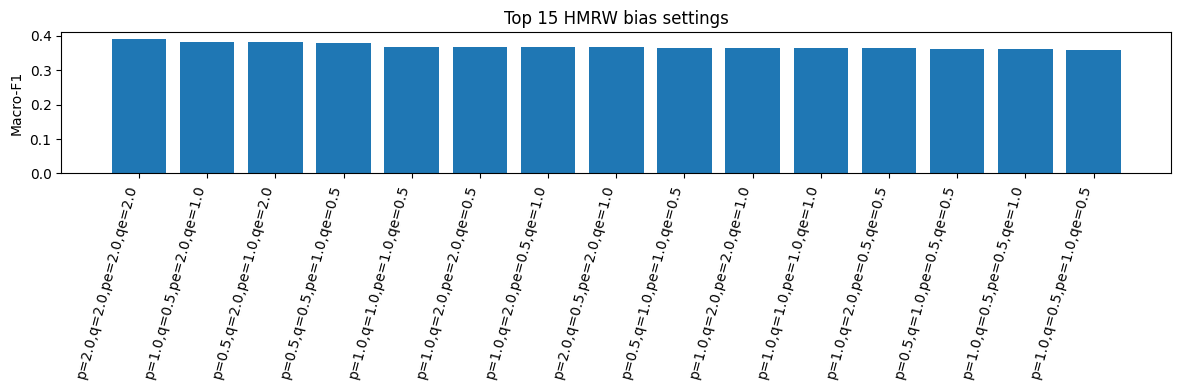

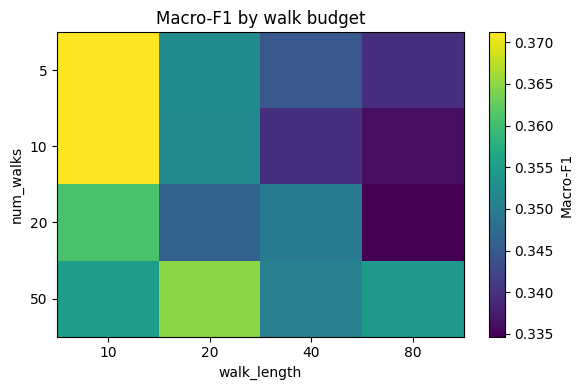

In [12]:
# --- Visual summaries ---
top_bias = bias_results.head(15).copy()
top_bias["label"] = top_bias.apply(
    lambda r: f"p={r.p},q={r.q},pe={r.p_edge},qe={r.q_edge}", axis=1
)

plt.figure(figsize=(12, 4))
plt.bar(range(len(top_bias)), top_bias["macro_f1"])
plt.xticks(range(len(top_bias)), top_bias["label"], rotation=75, ha="right")
plt.ylabel("Macro-F1")
plt.title("Top 15 HMRW bias settings")
plt.tight_layout()
plt.show()

pivot = budget_results.pivot_table(
    index="num_walks", columns="walk_length", values="macro_f1", aggfunc="mean"
)
plt.figure(figsize=(6, 4))
plt.imshow(pivot.values, aspect="auto")
plt.colorbar(label="Macro-F1")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("walk_length")
plt.ylabel("num_walks")
plt.title("Macro-F1 by walk budget")
plt.tight_layout()
plt.show()

In [13]:
# Save results for dissertation tables/plots
bias_results.to_csv("hmrw_bias_sweep.csv", index=False)
budget_results.to_csv("hmrw_budget_sweep.csv", index=False)
print("Saved: hmrw_bias_sweep.csv, hmrw_budget_sweep.csv")

Saved: hmrw_bias_sweep.csv, hmrw_budget_sweep.csv


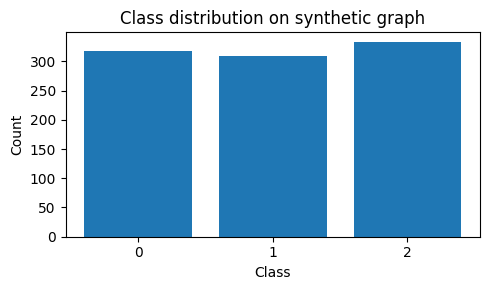

In [14]:
# --- Extra diagnostics: class balance in generated labels ---
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(5, 3))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Class distribution on synthetic graph")
plt.tight_layout()
plt.show()

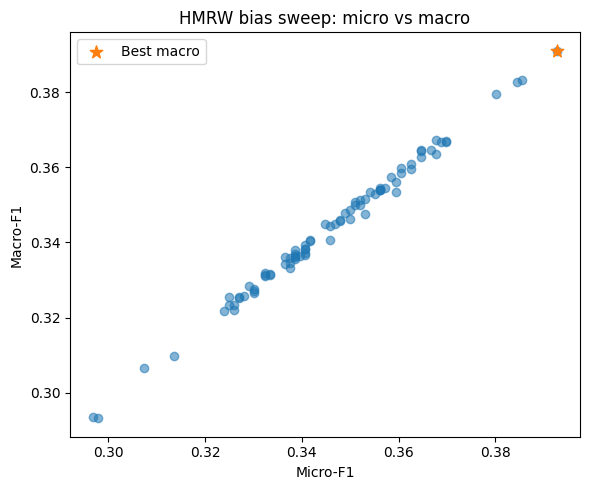

In [15]:
# --- Extra diagnostics: micro vs macro trade-off across all bias settings ---
plt.figure(figsize=(6, 5))
plt.scatter(bias_results["micro_f1"], bias_results["macro_f1"], alpha=0.55)

best_i = bias_results["macro_f1"].idxmax()
best_row = bias_results.loc[best_i]
plt.scatter([best_row["micro_f1"]], [best_row["macro_f1"]], s=90, marker="*", label="Best macro")

plt.xlabel("Micro-F1")
plt.ylabel("Macro-F1")
plt.title("HMRW bias sweep: micro vs macro")
plt.legend()
plt.tight_layout()
plt.show()

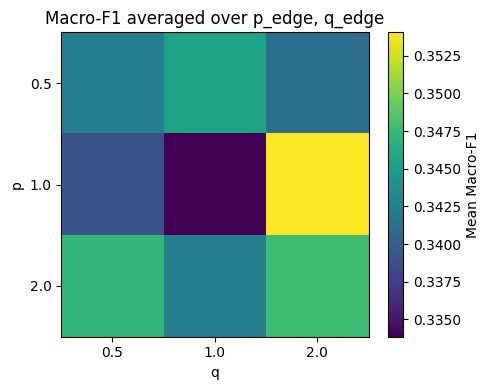

In [16]:
# --- Heatmap 1: average macro-F1 over (p, q), averaging over (p_edge, q_edge) ---
pq_heat = bias_results.pivot_table(
    index="p", columns="q", values="macro_f1", aggfunc="mean"
).sort_index().sort_index(axis=1)

plt.figure(figsize=(5, 4))
plt.imshow(pq_heat.values, aspect="auto")
plt.colorbar(label="Mean Macro-F1")
plt.xticks(range(len(pq_heat.columns)), pq_heat.columns)
plt.yticks(range(len(pq_heat.index)), pq_heat.index)
plt.xlabel("q")
plt.ylabel("p")
plt.title("Macro-F1 averaged over p_edge, q_edge")
plt.tight_layout()
plt.show()

In [17]:
# --- Sweep 3: context window k (keep other params at baseline) ---
rows = []
for window in [8, 10, 12, 14, 16, 18, 20]:
    params = dict(base_params)
    params.update(dict(window=window))
    X = hmrw_embeddings(H, seed=train_seed, **params)
    micro, macro = evaluate_embeddings(X, y, seed=train_seed)
    rows.append({"window": window, "micro_f1": micro, "macro_f1": macro})

window_results = pd.DataFrame(rows).sort_values("window")
window_results

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,window,micro_f1,macro_f1
0,8,0.339583,0.339053
1,10,0.346875,0.347307
2,12,0.351042,0.350089
3,14,0.340625,0.339403
4,16,0.350000,0.348492
5,18,0.348958,0.348225
6,20,0.350000,0.349546


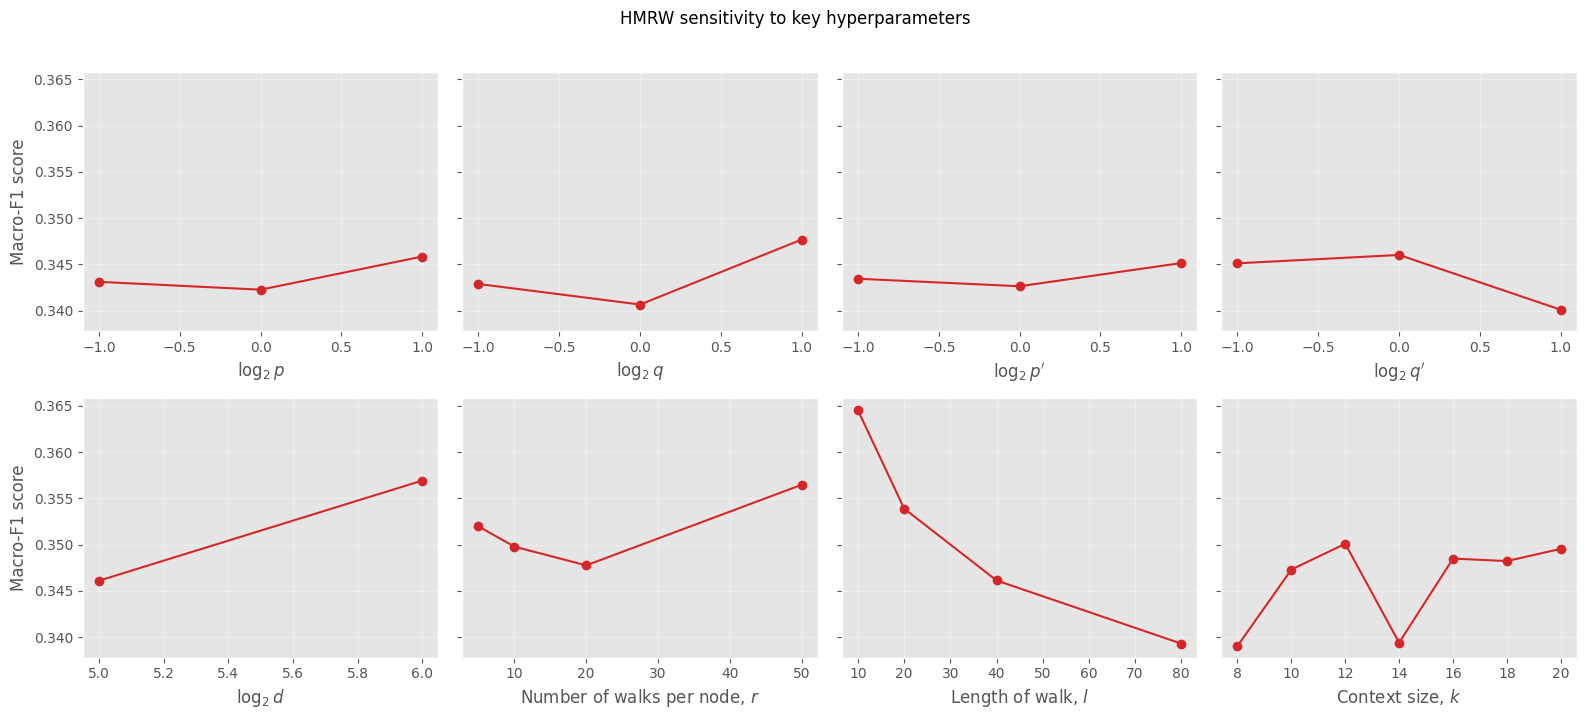

In [18]:
# --- 2x4 sensitivity plot (now includes p' and q') ---
plt.style.use("ggplot")

# Aggregate 1D curves by averaging over the other swept parameters
curve_p = bias_results.groupby("p", as_index=False)["macro_f1"].mean().sort_values("p")
curve_q = bias_results.groupby("q", as_index=False)["macro_f1"].mean().sort_values("q")
curve_p_edge = bias_results.groupby("p_edge", as_index=False)["macro_f1"].mean().sort_values("p_edge")
curve_q_edge = bias_results.groupby("q_edge", as_index=False)["macro_f1"].mean().sort_values("q_edge")
curve_d = budget_results.groupby("dim", as_index=False)["macro_f1"].mean().sort_values("dim")
curve_r = budget_results.groupby("num_walks", as_index=False)["macro_f1"].mean().sort_values("num_walks")
curve_l = budget_results.groupby("walk_length", as_index=False)["macro_f1"].mean().sort_values("walk_length")
curve_k = window_results.groupby("window", as_index=False)["macro_f1"].mean().sort_values("window")

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
(ax1, ax2, ax3, ax4), (ax5, ax6, ax7, ax8) = axes

ax1.plot(np.log2(curve_p["p"]), curve_p["macro_f1"], marker="o", color="tab:red")
ax1.set_xlabel(r"$\log_2 p$")
ax1.set_ylabel("Macro-F1 score")

ax2.plot(np.log2(curve_q["q"]), curve_q["macro_f1"], marker="o", color="tab:red")
ax2.set_xlabel(r"$\log_2 q$")

ax3.plot(np.log2(curve_p_edge["p_edge"]), curve_p_edge["macro_f1"], marker="o", color="tab:red")
ax3.set_xlabel(r"$\log_2 p'$")

ax4.plot(np.log2(curve_q_edge["q_edge"]), curve_q_edge["macro_f1"], marker="o", color="tab:red")
ax4.set_xlabel(r"$\log_2 q'$")

ax5.plot(np.log2(curve_d["dim"]), curve_d["macro_f1"], marker="o", color="tab:red")
ax5.set_xlabel(r"$\log_2 d$")
ax5.set_ylabel("Macro-F1 score")

ax6.plot(curve_r["num_walks"], curve_r["macro_f1"], marker="o", color="tab:red")
ax6.set_xlabel(r"Number of walks per node, $r$")

ax7.plot(curve_l["walk_length"], curve_l["macro_f1"], marker="o", color="tab:red")
ax7.set_xlabel(r"Length of walk, $l$")

ax8.plot(curve_k["window"], curve_k["macro_f1"], marker="o", color="tab:red")
ax8.set_xlabel(r"Context size, $k$")

for ax in axes.ravel():
    ax.grid(True, alpha=0.35)

fig.suptitle("HMRW sensitivity to key hyperparameters", y=1.02)
plt.tight_layout()
plt.show()

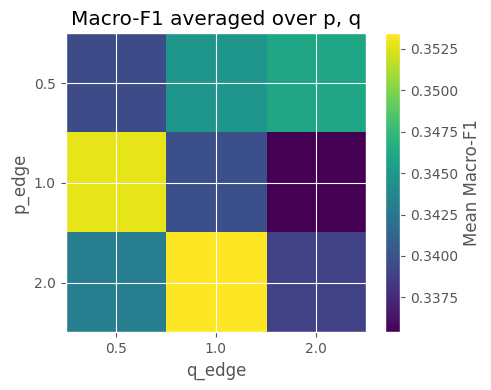

In [19]:
# --- Heatmap 2: average macro-F1 over (p_edge, q_edge), averaging over (p, q) ---
peqe_heat = bias_results.pivot_table(
    index="p_edge", columns="q_edge", values="macro_f1", aggfunc="mean"
).sort_index().sort_index(axis=1)

plt.figure(figsize=(5, 4))
plt.imshow(peqe_heat.values, aspect="auto")
plt.colorbar(label="Mean Macro-F1")
plt.xticks(range(len(peqe_heat.columns)), peqe_heat.columns)
plt.yticks(range(len(peqe_heat.index)), peqe_heat.index)
plt.xlabel("q_edge")
plt.ylabel("p_edge")
plt.title("Macro-F1 averaged over p, q")
plt.tight_layout()
plt.show()